# FinPilot — results notebook
Veritas AI High School Hackathon 2026 · AI + Finance.

This notebook rebuilds the data, retrains every model and prints the results on test data the models never saw.

> **This project is a prototype and is not financial advice.**

## 0. Setup
In Colab this clones the repository and installs the packages. Locally it just uses the project folder.

In [1]:
import os, sys, json, subprocess
if 'google.colab' in sys.modules:
    !git clone -q https://github.com/masalihx/FinFam.git
    %cd FinFam
    !pip -q install -r requirements.txt
elif os.path.basename(os.getcwd()) == 'notebooks':
    os.chdir('..')
PY = sys.executable
def run(script):
    out = subprocess.run([PY, script], capture_output=True, text=True)
    print('\n'.join(l for l in (out.stdout + out.stderr).splitlines() if 'Warning' not in l and 'warn' not in l))
print('Ready:', os.path.basename(os.getcwd()))

Ready: finpilot


## 1. Data
Open synthetic bank data for 100 US families (Misata, CC BY 4.0) and 68k bank descriptions (DoDataThings, MIT), mapped to 16 shared categories.

In [2]:
run('ml/data_prep.py')

Training descriptions: 68,000, 16 categories
Family transactions: 148,936 (97.9% have a unified category)
Families: 100


## 2. ML part 1 — categorization
Trained on one dataset, tested on 50 families from another dataset; then learning from user corrections.

In [3]:
run('ml/train_categorizer.py')

Train: 68,000 descriptions | Dev: 81,834 | Test: 63,974 family transactions
dev: constant_baseline = 0.001, keyword_baseline = 0.653, model = 0.680
test: constant_baseline = 0.002, keyword_baseline = 0.650, model = 0.692
Learning from corrections:
  after   0 corrections: macro-F1 = 0.692
  after  10 corrections: macro-F1 = 0.710
  after  50 corrections: macro-F1 = 0.743
  after 200 corrections: macro-F1 = 0.836
Saved model to ml/models/categorizer.joblib and results to ml/results/categorizer.json


## 3. ML part 3 — overspend risk
On day 5/10/15/20/25: will this family end the month above its usual level in a category? Train 2025, test Apr–Sep 2026.

In [4]:
run('ml/train_overspend.py')
run('ml/check_live_features.py')

Examples: train 33,945 | val 8,480 | test 17,030; overspend rate in test 39.5%
 baseline_proportion: precision=0.686, recall=0.676, f1=0.681, pr_auc=0.754
       baseline_pace: precision=0.677, recall=0.742, f1=0.708, pr_auc=0.742
               model: precision=0.774, recall=0.69, f1=0.729, pr_auc=0.853, brier=0.1343
By check day (recall / precision):
  day  5: proportion 0.45/0.59 | model 0.55/0.62
  day 10: proportion 0.59/0.65 | model 0.62/0.69
  day 15: proportion 0.70/0.68 | model 0.68/0.77
  day 20: proportion 0.78/0.72 | model 0.76/0.86
  day 25: proportion 0.87/0.76 | model 0.84/0.92
Saved model and results (ml/results/overspend.json)


All features match.


## 4. ML part 2 — recurring payments
Finds rent, bills and subscriptions, predicts the next payment. 30% of families held out.

In [5]:
run('ml/train_recurring.py')

Series: train 7,215 | test 2,805 | recurring share 13.3%
{
 "baseline_3_times_3_months": {
  "precision": 0.165,
  "recall": 0.895,
  "f1": 0.278
 },
 "model": {
  "precision": 0.956,
  "recall": 0.976,
  "f1": 0.966
 }
}
{
 "series_checked": 275,
 "baseline_last_plus_30_days": {
  "median_days_off": 0.0,
  "within_3_days": 0.84,
  "median_amount_error": 0.0
 },
 "model": {
  "median_days_off": 0.0,
  "within_3_days": 0.96,
  "median_amount_error": 0.0
 }
}


## 5. ML part 4 — market price
Ridge regression on product titles (Amazon Products 2023). Gemini comparison and the hybrid blend need a `GEMINI_API_KEY`; without it the saved results are shown.

In [6]:
if os.environ.get('GEMINI_API_KEY'):
    run('ml/train_price.py'); run('ml/price_hybrid.py'); run('ml/gemini_baselines.py')
print(json.dumps(json.load(open('ml/results/price_hybrid.json'))['test'], indent=1))

{
 "baseline_category_median": {
  "median_abs_pct_error": 0.543,
  "within_25pct": 0.25
 },
 "our_model": {
  "median_abs_pct_error": 0.374,
  "within_25pct": 0.34
 },
 "gemini": {
  "median_abs_pct_error": 0.258,
  "within_25pct": 0.46
 },
 "hybrid": {
  "median_abs_pct_error": 0.261,
  "within_25pct": 0.48,
  "range_coverage": 0.48,
  "median_range_width_ratio": 1.57
 }
}


## 6. ML part 5 — verdict backtest (the main number)
Every online purchase of $20+ in Apr–Sep 2026 is replayed as if the extension were open. All methods postpone the same number of purchases.

In [7]:
run('ml/backtest_verdict.py')

         rule_50_30_20: postponed 696 (17%), precision 0.63, recall 0.21, avoided $201/family-month, false alarms 256
            proportion: postponed 696 (17%), precision 0.82, recall 0.27, avoided $232/family-month, false alarms 126
  overspend_model_only: postponed 696 (17%), precision 0.99, recall 0.33, avoided $286/family-month, false alarms 4
               verdict: postponed 696 (17%), precision 0.66, recall 0.22, avoided $285/family-month, false alarms 236
{'high_risk': 337, 'above_usual_price': 486, 'both': 127}


## 7. Assistant intents

In [8]:
run('ml/train_intent.py')

Train phrases: 361, test questions: 47
Keyword baseline: accuracy 0.553, macro-F1 0.587
Model:            accuracy 0.723, macro-F1 0.698
  model error: 'sum of my clothing purchases' -> budget_left (true spending)
  model error: 'are we going to blow the grocery budget' -> goals (true budget_left)
  model error: 'are we spending too fast this month' -> spending (true budget_left)
  model error: 'update me on my targets' -> spending (true goals)
  model error: "what's eating my budget" -> budget_left (true where_losing)
  model error: 'help me spend less' -> help (true where_losing)
  model error: 'which category grew the most' -> goals (true where_losing)
  model error: 'how do we cut costs' -> goals (true where_losing)
  model error: 'things i put off buying' -> can_afford (true postponed)
  model error: 'how much have i not spent thanks to waiting' -> spending (true postponed)
  model error: 'which charges are about to hit our account' -> goals (true upcoming)
  model error: 'calenda

## 8. Summary tables and charts

In [9]:
import pandas as pd, matplotlib.pyplot as plt
R = {n: json.load(open(f'ml/results/{n}.json')) for n in ['categorizer','overspend','recurring','price_hybrid','backtest_verdict','intent','gemini_baselines']}
rows = [
 ('Categorization (macro-F1)', 'keywords', R['categorizer']['test']['keyword_baseline'], R['categorizer']['test']['model']),
 ('Overspend (PR-AUC)', 'proportion', R['overspend']['test']['baseline_proportion']['pr_auc'], R['overspend']['test']['model']['pr_auc']),
 ('Recurring (F1)', '3 times in 3 months', R['recurring']['detection']['baseline_3_times_3_months']['f1'], R['recurring']['detection']['model']['f1']),
 ('Market price (within ±25%)', 'category median', R['price_hybrid']['test']['baseline_category_median']['within_25pct'], R['price_hybrid']['test']['hybrid']['within_25pct']),
 ('Assistant intents (macro-F1)', 'keywords', R['intent']['keyword_baseline']['macro_f1'], R['intent']['model']['macro_f1']),
]
pd.DataFrame(rows, columns=['Task', 'Baseline', 'Baseline score', 'Our model'])

Matplotlib is building the font cache; this may take a moment.


,Task,Baseline,Baseline score,Our model
0,Categorization (macro-F1),keywords,0.6505,0.6923
1,Overspend (PR-AUC),proportion,0.7540,0.8530
2,Recurring (F1),3 times in 3 months,0.2780,0.9660
3,Market price (within ±25%),category median,0.2500,0.4800
4,Assistant intents (macro-F1),keywords,0.5870,0.6980


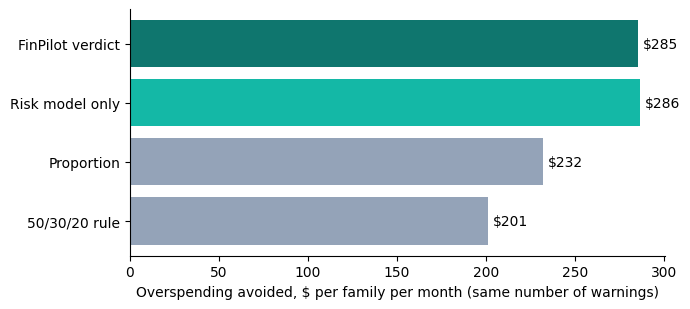

In [10]:
b = R['backtest_verdict']['same_number_of_warnings']
names = {'rule_50_30_20':'50/30/20 rule','proportion':'Proportion','overspend_model_only':'Risk model only','verdict':'FinPilot verdict'}
vals = [b[k]['avoided_per_family_month_usd'] for k in names]
fig, ax = plt.subplots(figsize=(7,3.2))
ax.barh(list(names.values()), vals, color=['#94a3b8','#94a3b8','#14b8a6','#0f766e'])
for i, v in enumerate(vals): ax.text(v+3, i, f'${v:.0f}', va='center')
ax.set_xlabel('Overspending avoided, $ per family per month (same number of warnings)')
ax.spines[['top','right']].set_visible(False); plt.tight_layout(); plt.show()

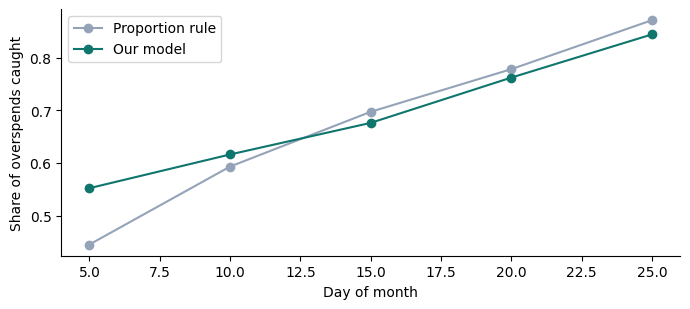

In [11]:
d = R['overspend']['by_day']
days = sorted(d, key=int)
fig, ax = plt.subplots(figsize=(7,3.2))
ax.plot([int(x) for x in days], [d[x]['proportion']['recall'] for x in days], marker='o', label='Proportion rule', color='#94a3b8')
ax.plot([int(x) for x in days], [d[x]['model']['recall'] for x in days], marker='o', label='Our model', color='#0f766e')
ax.set_xlabel('Day of month'); ax.set_ylabel('Share of overspends caught'); ax.legend(); ax.spines[['top','right']].set_visible(False)
plt.tight_layout(); plt.show()

## 9. Where it fails
Error examples saved by each script:

In [12]:
print('Verdict, flagged but the month ended fine:')
for e in R['backtest_verdict']['error_examples']['not_worth_it_but_fine']: print(' ', e['label'], e['price'], e['description'][:40])
print('Verdict, said Buy but the month went over:')
for e in R['backtest_verdict']['error_examples']['buy_but_harmful']: print(' ', e['label'], e['price'], e['description'][:40])
print('Categorization:')
for e in R['categorizer']['error_examples'][:4]: print(' ', e)
print('Recurring false alarms:')
for e in R['recurring']['error_examples']['false_alarm']: print(' ', e['key'])
print('Assistant:')
for e in R['intent']['model_errors'][:4]: print(' ', e)

Verdict, flagged but the month ended fine:
  shopping 1458.47 AMAZON MKTPL*5BA8GD073 Amzn.com/bill WA
  shopping 1072.79 Debit Card Purchase - WF WAYFAIR43704974
  shopping 861.14 AMAZON MKTPL*BBV8JRE93 Amzn.com/bill WA
Verdict, said Buy but the month went over:
  shopping 542.26 AMAZON MKTPL*LFGJ2Y2H3 Amzn.com/bill WA
  shopping 417.36 AMAZON MKTPL*485K11433 Amzn.com/bill WA
  shopping 377.69 WALMART.COM BENTONVILLE AR
Categorization:
  {'text': '[credit] Zelle Payment From Alejandro Contreras 3459549392', 'true': 'transfer', 'predicted': 'income'}
  {'text': '[credit] Zelle Payment From Amanda Webb 4464263979', 'true': 'transfer', 'predicted': 'income'}
  {'text': '[debit] Card Purchase 10/01 7-Eleven 25943 Chicago IL Card 1693', 'true': 'groceries', 'predicted': 'shopping'}
  {'text': '[debit] Card Purchase 11/06 7-Eleven 28456 Chicago IL Card 1693', 'true': 'groceries', 'predicted': 'shopping'}
Recurring false alarms:
  capital one mobile pmt web id:
  capital one mobile pymt
  pur

> This project is a prototype and is not financial advice.